In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
tumor = "t46"



In [3]:
#A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_new_population_assignments_A.txt", sep="\t")

In [4]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [5]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A1
A21
A221
A2221
A2222


In [6]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

variants_with_vaf = pd.read_csv(f"../data/{tumor}/{tumor}.vaf.txt", sep = "\t")

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]



In [7]:
high_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]>=0.3]

In [8]:
low_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]<0.05]

In [9]:
low_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
189,chr10,26470742,G,T,0.046512
346,chr10,50333203,A,G,0.047619
496,chr10,71048093,C,T,0.039474
518,chr10,76451844,A,T,0.031746
538,chr10,78967058,G,T,0.047619


In [10]:
high_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
5,chr10,797816,T,G,0.631579
9,chr10,1313047,C,A,0.550000
11,chr10,1496076,G,T,0.392157
13,chr10,1908542,C,T,0.500000
14,chr10,1952424,C,G,0.425000


In [11]:
len(high_freq_variants), len(low_freq_variants)

(8137, 314)

In [12]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,103683,AAAACCAAAGTAGTTCT,0,0,0,1,1,0,1
1,chr10,103683,TTGCGTTTTACGTTATT,0,1,0,0,0,1,1
2,chr10,103683,TAGTCAGGTGACAATAT,0,0,0,1,1,0,1
3,chr10,103683,GAGATAAGCCTCACTCT,0,1,0,0,0,1,1
4,chr10,103683,ACGGGAAAGGCCTGTCC,0,0,0,1,1,0,1


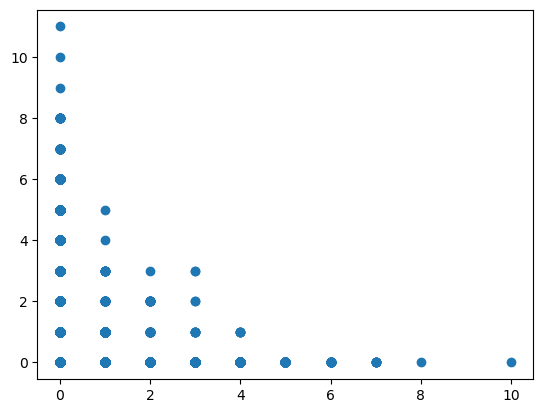

In [13]:
plt.plot(tumor_variants_real['alt_count'], tumor_variants_real['ref_count'], 'o')

In [14]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [15]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [16]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A1 (normal),263,18835,326,153,18829,23,23
1,A21,487,38874,9177,487,39629,50,46
2,A221,186,17908,4442,186,18258,21,21
3,A2221,194,19344,4766,194,19560,22,21
4,A2222,238,20928,5130,238,21340,28,25


In [17]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [18]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A1 (normal),263,18835,326,153,18829,23,23,0.017308,0.001222,1.239544,0.087452
1,A21,487,38874,9177,487,39629,50,46,0.236070,0.001262,18.843943,0.102669
2,A221,186,17908,4442,186,18258,21,21,0.248046,0.001150,23.881720,0.112903
3,A2221,194,19344,4766,194,19560,22,21,0.246381,0.001125,24.567010,0.113402
4,A2222,238,20928,5130,238,21340,28,25,0.245126,0.001312,21.554622,0.117647


In [19]:
# Above analysis for just the high frequency variants (variants defined by CHROM and POS)
high_freq_loci = high_freq_variants[['CHROM', 'POS']].values.tolist()
low_freq_loci = low_freq_variants[['CHROM', 'POS']].values.tolist()
# Restrict tumor_variants_real to just these loci
tumor_variants_real_hf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in high_freq_loci])]
tumor_variants_real_lf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in low_freq_loci])]

In [20]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_hf[tumor_variants_real_hf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [21]:
# Create the summary table
variant_summary_hf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [22]:
variant_summary_hf["variant_frequency"] = variant_summary_hf["variant_observed"]/variant_summary_hf["opportunities_for_variants"]
variant_summary_hf["pseudo_frequency"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["opportunities_for_pseudo"]
variant_summary_hf["variant_per_cell"] = variant_summary_hf["variant_observed"]/variant_summary_hf["Num_Cells"]
variant_summary_hf["pseudo_per_cell"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["Num_Cells"]

In [23]:
variant_summary_hf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A1 (normal),263,7393,75,44,18829,23,23,0.010145,0.001222,0.285171,0.087452
1,A21,487,13371,5770,486,39629,50,46,0.431531,0.001262,11.848049,0.102669
2,A221,186,6389,2836,185,18258,21,21,0.443888,0.001150,15.247312,0.112903
3,A2221,194,6612,3007,194,19560,22,21,0.454779,0.001125,15.500000,0.113402
4,A2222,238,7165,3152,237,21340,28,25,0.439916,0.001312,13.243697,0.117647


In [24]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [25]:
# Create the summary table
variant_summary_lf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [26]:
variant_summary_lf["variant_frequency"] = variant_summary_lf["variant_observed"]/variant_summary_lf["opportunities_for_variants"]
variant_summary_lf["pseudo_frequency"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["opportunities_for_pseudo"]
variant_summary_lf["variant_per_cell"] = variant_summary_lf["variant_observed"]/variant_summary_lf["Num_Cells"]
variant_summary_lf["pseudo_per_cell"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["Num_Cells"]

In [27]:
variant_summary_lf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A1 (normal),263,338,7,7,18829,23,23,0.020710,0.001222,0.026616,0.087452
1,A21,487,903,23,21,39629,50,46,0.025471,0.001262,0.047228,0.102669
2,A221,186,457,9,9,18258,21,21,0.019694,0.001150,0.048387,0.112903
3,A2221,194,467,15,15,19560,22,21,0.032120,0.001125,0.077320,0.113402
4,A2222,238,496,20,19,21340,28,25,0.040323,0.001312,0.084034,0.117647


In [28]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]
normal_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [29]:
pos_groups = tumor_info.groupby(["chrom", "pos"])
pos_groups_normal = normal_info.groupby(["chrom", "pos"])

In [30]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,103683,TTGCGTTTTACGTTATT,0,1,0,0,0,1,1
2,chr10,103683,TAGTCAGGTGACAATAT,0,0,0,1,1,0,1
3,chr10,103683,GAGATAAGCCTCACTCT,0,1,0,0,0,1,1
4,chr10,103683,ACGGGAAAGGCCTGTCC,0,0,0,1,1,0,1
5,chr10,103683,GACACGTGCAGGTCTGT,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
178527,chrY,59000895,AATGAGAACCGAACACA,0,0,2,0,2,0,2
178528,chrY,59000895,CAAATTCGACTTTCTGT,0,0,1,0,1,0,1
178531,chrY,59000895,TAAACTGAACCCCGTGA,0,0,1,0,1,0,1
178532,chrY,59000895,GCATCGGAACAATCTCG,0,0,1,0,1,0,1


In [31]:
#unique_positions = high_freq_loci
unique_positions = low_freq_loci

In [32]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,103683,TTGCGTTTTACGTTATT,0,1,0,0,0,1,1
2,chr10,103683,TAGTCAGGTGACAATAT,0,0,0,1,1,0,1
3,chr10,103683,GAGATAAGCCTCACTCT,0,1,0,0,0,1,1
4,chr10,103683,ACGGGAAAGGCCTGTCC,0,0,0,1,1,0,1
5,chr10,103683,GACACGTGCAGGTCTGT,0,0,0,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...
178527,chrY,59000895,AATGAGAACCGAACACA,0,0,2,0,2,0,2
178528,chrY,59000895,CAAATTCGACTTTCTGT,0,0,1,0,1,0,1
178531,chrY,59000895,TAAACTGAACCCCGTGA,0,0,1,0,1,0,1
178532,chrY,59000895,GCATCGGAACAATCTCG,0,0,1,0,1,0,1


In [33]:
# p = unique_positions[0]
# df = pos_groups.get_group((p[0], p[1]))


In [34]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

tumor_variant_summary = pd.DataFrame(row_list)

In [35]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups_normal.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

normal_variant_summary = pd.DataFrame(row_list)

In [36]:
tumor_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,26470742,9,0,9,0.0
1,chr10,50333203,10,0,10,0.0
2,chr10,71048093,14,0,14,0.0
3,chr10,76451844,11,0,11,0.0
4,chr10,78967058,8,0,8,0.0


In [37]:
tumor_variant_summary_hc = tumor_variant_summary[tumor_variant_summary["total_count"] >= 10]
normal_variant_summary_hc = normal_variant_summary[normal_variant_summary["total_count"] >= 10]

In [38]:
normal_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,26470742,0,0,0,NaN
1,chr10,50333203,3,0,3,0.0
2,chr10,71048093,0,0,0,NaN
3,chr10,76451844,0,0,0,NaN
4,chr10,78967058,2,0,2,0.0


In [39]:
#merge tumor and normal variant summaries
merged_variant_summary = tumor_variant_summary.merge(normal_variant_summary, on=["chrom", "pos"], suffixes=("_tumor", "_normal"))

In [40]:
merged_variant_summary.dropna(inplace=True)

In [41]:
#merged_variant_summary[["chrom", "pos", "alt_count_tumor", "total_count_tumor","alt_count_normal", "total_count_normal"]].to_csv(f"../data/{tumor}/{tumor}_variant_summary_for_Mike.txt", sep="\t", index=False)

In [42]:
merged_variant_summary["total"] = merged_variant_summary["total_count_tumor"] + merged_variant_summary["total_count_normal"]

In [43]:
merged_variant_summary.head()

,chrom,pos,ref_count_tumor,alt_count_tumor,total_count_tumor,variant_frequency_tumor,ref_count_normal,alt_count_normal,total_count_normal,variant_frequency_normal,total
1,chr10,50333203,10,0,10,0.00,3,0,3,0.0,13
4,chr10,78967058,8,0,8,0.00,2,0,2,0.0,10
5,chr10,79835567,9,0,9,0.00,1,0,1,0.0,10
8,chr10,104883967,4,0,4,0.00,1,0,1,0.0,5
9,chr10,127575213,97,3,100,0.03,13,0,13,0.0,113


In [44]:

merged_variant_summary = merged_variant_summary[merged_variant_summary["total"] >= 10]

In [45]:
merged_variant_summary

,chrom,pos,ref_count_tumor,alt_count_tumor,total_count_tumor,variant_frequency_tumor,ref_count_normal,alt_count_normal,total_count_normal,variant_frequency_normal,total
1,chr10,50333203,10,0,10,0.000000,3,0,3,0.0,13
4,chr10,78967058,8,0,8,0.000000,2,0,2,0.0,10
5,chr10,79835567,9,0,9,0.000000,1,0,1,0.0,10
9,chr10,127575213,97,3,100,0.030000,13,0,13,0.0,113
10,chr10,127575217,95,3,98,0.030612,13,0,13,0.0,111
...,...,...,...,...,...,...,...,...,...,...,...
304,chrX,15594249,27,0,27,0.000000,6,0,6,0.0,33
306,chrX,31914427,31,0,31,0.000000,4,0,4,0.0,35
307,chrX,38994732,19,0,19,0.000000,4,0,4,0.0,23
312,chrY,58996765,36,0,36,0.000000,6,0,6,0.0,42


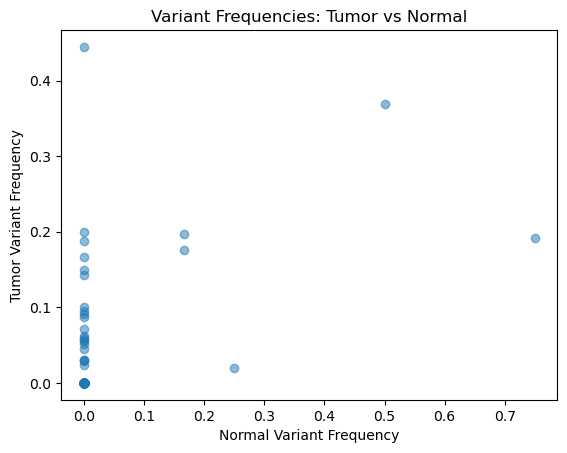

In [46]:
plt.scatter(merged_variant_summary["variant_frequency_normal"], merged_variant_summary["variant_frequency_tumor"], alpha=0.5)
plt.xlabel("Normal Variant Frequency")
plt.ylabel("Tumor Variant Frequency")
plt.title("Variant Frequencies: Tumor vs Normal")
plt.show()

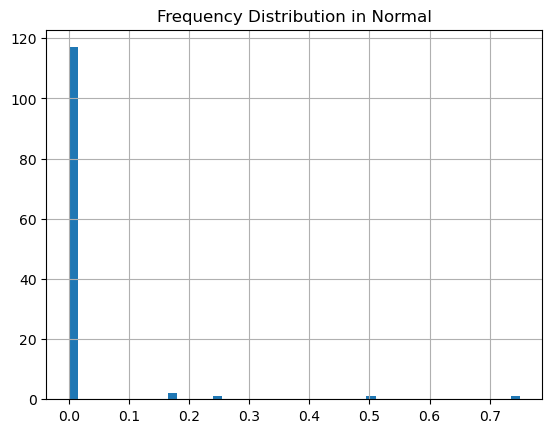

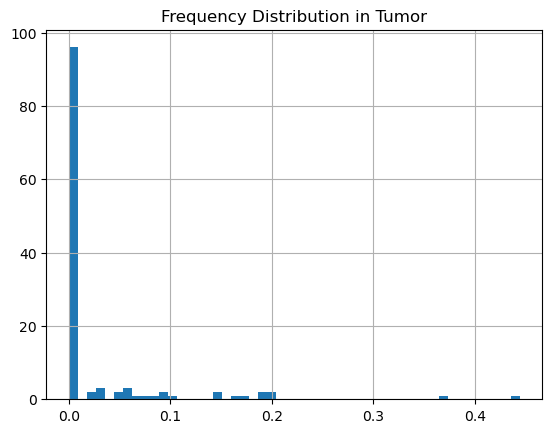

In [47]:
merged_variant_summary["variant_frequency_normal"].hist(bins=50)
plt.title("Frequency Distribution in Normal")
plt.show()
merged_variant_summary["variant_frequency_tumor"].hist(bins=50)
plt.title("Frequency Distribution in Tumor")
plt.show()

In [48]:
merged_variant_summary[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

,variant_frequency_normal,variant_frequency_tumor
variant_frequency_normal,1.000000,0.487252
variant_frequency_tumor,0.487252,1.000000


In [49]:
tumor_variants_real_lf.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
299,chr10,26470742,AACAAGAGTCACGGTTG,0,0,0,2,2,0,2
697,chr10,50333203,AGCAGGATTGGTTGATA,1,0,0,0,1,0,1
698,chr10,50333203,ACCAGAAAAGGCACAGC,1,0,0,0,1,0,1
946,chr10,71048093,ATGAGATTGACTATAGT,0,0,1,0,1,0,1
999,chr10,76451844,AAATCGCTGTTTTGATA,1,0,0,0,1,0,1


In [50]:
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())




96
0
21
5


In [51]:
non_zero_somewhere = merged_variant_summary[(merged_variant_summary["variant_frequency_normal"]!=0) | (merged_variant_summary["variant_frequency_tumor"]!=0)]

In [52]:
non_zero_somewhere[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

,variant_frequency_normal,variant_frequency_tumor
variant_frequency_normal,1.000000,0.375872
variant_frequency_tumor,0.375872,1.000000


In [53]:
info_df_grps_dict = {}
for pop in A_dict.keys():
    cells = A_dict[pop]['cells']
    df = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(cells)]
    info_df_grps_dict[pop] = df




In [54]:
variant_summary_df_dict = {}
for pop in info_df_grps_dict.keys():
    df = info_df_grps_dict[pop]
    pos_groups = df.groupby(['chrom', 'pos'])
    
    row_list = []
    for p in low_freq_loci:
        try:
            group_df = pos_groups.get_group((p[0], p[1]))
            r_count = group_df["ref_count"].sum()
            a_count = group_df["alt_count"].sum()
            tot = group_df["total_count"].sum()
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": r_count,
                "alt_count": a_count,
                "total_count": tot,
                "variant_frequency": a_count / tot
            })
        except:
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": 0,
                "alt_count": 0,
                "total_count": 0,
                "variant_frequency": None
            })
    
    variant_summary_df_dict[pop] = pd.DataFrame(row_list)


In [55]:
# merge all population variant summaries into a single dataframe
merged_pop_variant_summary = None
for pop in variant_summary_df_dict.keys():
    df = variant_summary_df_dict[pop][["chrom", "pos","total_count", "alt_count"]]
    df = df.rename(columns={"total_count": f"total_count_{pop}", "alt_count": f"alt_count_{pop}"})
    if merged_pop_variant_summary is None:
        merged_pop_variant_summary = df
    else:
        merged_pop_variant_summary = merged_pop_variant_summary.merge(df, on=["chrom", "pos"], how="outer") 

In [56]:
merged_pop_variant_summary["total_count"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("total_count_")]].sum(axis=1)

In [57]:
merged_pop_variant_summary.head()

,chrom,pos,total_count_A1,alt_count_A1,total_count_A21,alt_count_A21,total_count_A221,alt_count_A221,total_count_A2221,alt_count_A2221,total_count_A2222,alt_count_A2222,total_count
0,chr1,69595824,0,0,1,0,0,0,0,0,2,0,3
1,chr1,75085331,3,0,7,0,4,0,1,0,0,0,15
2,chr1,85985614,0,0,4,0,1,0,2,0,2,0,9
3,chr1,96412918,0,0,2,0,1,0,3,0,1,0,7
4,chr1,120236402,1,0,0,0,0,0,0,0,0,0,1


In [ ]:
#merged_pop_variant_summary = merged_pop_variant_summary[merged_pop_variant_summary["total_count"] >= 10]

In [ ]:
merged_pop_variant_summary.head()

In [ ]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 5]["variant_frequency"].hist(bins=50) 

In [ ]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 5)]["variant_frequency"].hist(bins=50)

In [ ]:
well_covered_non_zero_variants = tumor_variant_summary[(tumor_variant_summary["total_count"] > 20) & (tumor_variant_summary["variant_frequency"] > 0)]

In [ ]:
tumor_clones = [ t for t in A_dict.keys() if t != normal_A ]

In [ ]:
t = tumor_clones[0]

In [ ]:
tumor_variants_real.head()

In [ ]:
unique_positions = well_covered_non_zero_variants[["chrom", "pos"]].drop_duplicates().values.tolist()

In [ ]:
vaf_list = []

for t in A_dict.keys():
    # Get variant data for this tumor clone

    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    #unique_positions = tumor_clone_info[["chrom", "pos"]].drop_duplicates().values.tolist()
    
    vaf_spread = []
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    
    vaf_list.append(vaf_spread)  # This should be OUTSIDE the position loop

# Now plot
plt.figure(figsize=(10, 6))
plt.boxplot(vaf_list, labels=A_dict.keys())
plt.ylabel("VAF")
plt.xlabel("Tumor Clone")
plt.title("VAF Spread Across Tumor Clones")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()
# plt.xlabel("VAF")
# plt.ylabel("Frequency")
# plt.title("VAF Distribution Across Tumor Clones")
# plt.legend()
# plt.show()

In [ ]:
well_covered = tumor_variant_summary[(tumor_variant_summary["alt_count"] > 3) & (tumor_variant_summary["total_count"] > 10) ]

In [ ]:
well_covered["variant_frequency"].hist(bins=50)

In [ ]:
unique_positions = well_covered[["chrom", "pos"]].drop_duplicates().values.tolist()
vaf_list = []
row_list = []
for t in A_dict.keys():
    # Get variant data for this tumor clone
    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    vaf_spread = []
    var_count = 0
    tot_count = 0
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            var_count += a_count
            tot_count += tot
            
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    row_list.append({"tumor_clone": t, "var_count": var_count, "tot_count": tot_count, "vaf": var_count/tot_count})
    
    vaf_list.append(vaf_spread)  
    
    

In [ ]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()

In [ ]:
pd.DataFrame(row_list)

In [ ]:
len(unique_positions)

In [ ]:
len(high_freq_loci)

In [ ]:
info_df_grps_dict = {}
for pop in A_dict.keys():
    cells = A_dict[pop]['cells']
    df = tumor_variants_real_hf[tumor_variants_real_hf['cell_id'].isin(cells)]
    info_df_grps_dict[pop] = df

In [ ]:
variant_summary_df_dict = {}
for pop in info_df_grps_dict.keys():
    df = info_df_grps_dict[pop]
    pos_groups = df.groupby(['chrom', 'pos'])
    
    row_list = []
    for p in high_freq_loci:
        try:
            group_df = pos_groups.get_group((p[0], p[1]))
            r_count = group_df["ref_count"].sum()
            a_count = group_df["alt_count"].sum()
            tot = group_df["total_count"].sum()
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": r_count,
                "alt_count": a_count,
                "total_count": tot,
                "variant_frequency": a_count / tot
            })
        except:
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": 0,
                "alt_count": 0,
                "total_count": 0,
                "variant_frequency": None
            })
    
    variant_summary_df_dict[pop] = pd.DataFrame(row_list)


In [ ]:
# merge all population variant summaries into a single dataframe
merged_pop_variant_summary = None
for pop in variant_summary_df_dict.keys():
    df = variant_summary_df_dict[pop][["chrom", "pos","total_count", "alt_count"]]
    df = df.rename(columns={"total_count": f"total_count_{pop}", "alt_count": f"alt_count_{pop}"})
    if merged_pop_variant_summary is None:
        merged_pop_variant_summary = df
    else:
        merged_pop_variant_summary = merged_pop_variant_summary.merge(df, on=["chrom", "pos"], how="outer") 

In [ ]:
merged_pop_variant_summary["total_count"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("total_count_")]].sum(axis=1)

In [ ]:
merged_pop_variant_summary = merged_pop_variant_summary[merged_pop_variant_summary["total_count"] != 0]

In [ ]:
merged_pop_variant_summary["alt_total"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("alt_count_")]].sum(axis=1)

In [ ]:
merged_pop_variant_summary.to_csv(f"../data/{tumor}/{tumor}_high_freq_variant_summary_by_population.txt", sep="\t", index=False)